The purpose of this notebooks is to explore advanced queries of the STREAM data.

In [1]:
import pyarrow.dataset as ds
from functools import reduce
from datetime import datetime

from stream_utils import S3hsclient

In [2]:
hs = S3hsclient.S3HydroShare()

Please Enter Your HydroShare Credentials


Username:  TonyCastronova
Password for TonyCastronova:  ········


MRB data exists in HydroShare at: https://hydroshare.org/resource/9fc3a923419640729b1606f0e64bd288/. To load these data, we'll use the HydroShare Python library.

In [3]:
resource_id = '9fc3a923419640729b1606f0e64bd288'
resource = hs.resource(resource_id)

This resource contains a number of files that can be loaded for analysis. To see which files are available we'll use the `ls` command.

In [4]:
resource.s3_ls()

['tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/dynamic_antropogenic.parquet',
 'tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/gauges.cpg',
 'tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/gauges.dbf',
 'tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/gauges.parquet',
 'tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/gauges.prj',
 'tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/gauges.shp',
 'tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/gauges.shx',
 'tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/gauges_meta.xml',
 'tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/gauges_resmap.xml',
 'tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/grab_samples.parquet',
 'tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/lulc.parquet',
 'tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/metadata.parquet',
 'tonycastronova/9fc3a92

## Multi-Filter Query

Create a dictionary of the files shown above to make them easier to work with in Python.

In [5]:
# Dictionary of Parquet files in the HydroShare resource (from above)
files = {
    "dynamic_anthropogenic": "tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/dynamic_antropogenic.parquet",
    "gauges": "tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/gauges.parquet",
    "grab_samples": "tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/grab_samples.parquet",
    "lulc": "tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/lulc.parquet",
    "streamflow": "tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/streamflow",
    "water_quality": "tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/water_quality",
    "metadata": "tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/metadata.parquet",
    "vaa": "tonycastronova/9fc3a923419640729b1606f0e64bd288/data/contents/vaa.parquet",
}

Define a function to loading the parquet datasets in HydroShare into Pandas-style dataframes. The purpose of this function is to keep our notebook code clean, since this is something that we'll use often.

In [6]:
def load_parquets_from_hydroshare(hs_instance, files = [], join_on=None):
    
    # Loop over the files above and load each file lazily
    dfs = []
    for f in files:
        dfs.append(
            ds.dataset(
                f,
                format="parquet",
                filesystem=hs.get_s3_filesystem(),
                ).to_table().to_pandas()
        )

    # perform a join if argument is provided
    if join_on is not None:
        dat = reduce(lambda left, right: left.merge(right, on=join_on, how="inner"), dfs)
        return dat

    # return the list of dfs if the join argument is not provided.
    return dfs

Benchmark querying data using joined dask dataframe. We're only going to load the `metadata` and `vaa` files right now so we can run some filtering to decide which sites we'd like to download data for.

In [7]:
%%time

# load the metadata and vaa files, joining them together using the
# "STREAM_ID" column.
dat = load_parquets_from_hydroshare(hs,
                                   files = [files['metadata'],
                                            files['vaa']],
                                    join_on = 'STREAM_ID')

CPU times: user 41.7 ms, sys: 18.1 ms, total: 59.8 ms
Wall time: 893 ms


In [8]:
%%time

# perform some sort of filtering. In this example, we're isolating
# all STREAM_IDs that have a drainage areas less that 100 sqkm and 
# are within there 050100 HUC06 boundary.
dat = dat[
    (dat.drainagearea_sqkm_x <= 100) \
  & (dat.huc06 == "050100")
    ]
dat

CPU times: user 3.47 ms, sys: 2.44 ms, total: 5.91 ms
Wall time: 3.97 ms


,STREAM_ID,sourceID,source,site name,latitude_wgs84,longitude_wgs84,drainagearea_sqkm_x,state_name_x,time_zone,WQ_parameters,...,nhdv2_comid,WTemp_C_count,SpC_uScm_count,DO_mgL_count,pH_count,Turb_FNU_count,Turb_NTU_count,NO3_mgNL_count,fDOM_QSU_count,fDOM_RFU_count
8,STREAM-gauge-1730,3022540,USGS,"Woodcock Creek at Blooming Valley, PA",41.690612,-80.048112,80.548689,Pennsylvania,Eastern,WTemp_C,...,9050351,102483.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10,STREAM-gauge-1732,3026480,USGS,"East Branch Clarion River near Clermont, PA",41.644056,-78.531444,21.548717,Pennsylvania,Eastern,WTemp_C,...,6874075,112492.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Our query isolated two STREAM_IDs that fit our criteria. We'll now use these specific STREAM_IDs to collect the data we're interested in, for example all of the water quality observations associated with them.

In [9]:
%%time


# read the 'water_quality' data using hive partitioning    
dataset = ds.dataset(
    files['water_quality'],
    format="parquet",
    filesystem=hs.get_s3_filesystem(),
    partitioning="hive"
)

CPU times: user 104 ms, sys: 8.32 ms, total: 113 ms
Wall time: 630 ms


In [11]:
%%time

# filter these data for the stream ids returned when we queried the metadata file
stream_ids = list(dat.STREAM_ID) 
result = dataset.to_table(
    filter=(
        (ds.field("STREAM_ID").isin(stream_ids))
    )
)
df = result.to_pandas()
df

CPU times: user 106 ms, sys: 46.9 ms, total: 153 ms
Wall time: 1.13 s


,DateTime,WTemp_C,Flag_WTemp_C,SpC_uScm,Flag_SpC_uScm,DO_mgL,Flag_DO_mgL,pH,Flag_pH,Turb_FNU,...,Flag_Turb_NTU,fDOM_QSU,Flag_fDOM_QSU,Chla_ugL,Flag_Chla_ugL,PC_RFU,Flag_PC_RFU,fDOM_RFU,Flag_fDOM_RFU,STREAM_ID
0,2013-08-09 04:00:00,20.350,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-1730
1,2013-08-09 05:00:00,20.225,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-1730
2,2013-08-09 06:00:00,20.100,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-1730
3,2013-08-09 07:00:00,20.025,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-1730
4,2013-08-09 08:00:00,19.925,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-1730
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112487,2025-08-10 14:00:00,17.700,P,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-1732
112488,2025-08-10 15:00:00,17.825,P,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-1732
112489,2025-08-10 16:00:00,18.000,P,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-1732
112490,2025-08-10 17:00:00,18.300,P,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-1732


Plot these data.

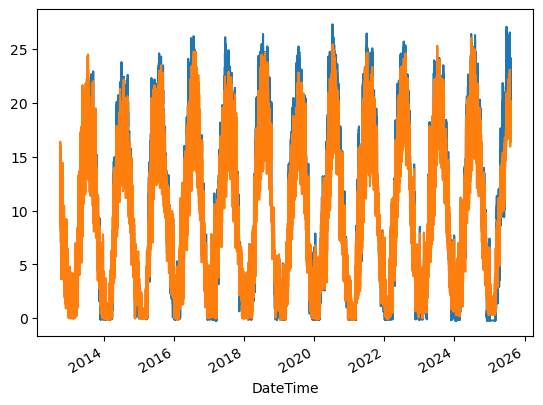

In [11]:
for group_name, group_df in df.groupby(df.STREAM_ID):
    group_df.set_index('DateTime', inplace=True)
    group_df.WTemp_C.plot()

CPU times: user 301 ms, sys: 29.5 ms, total: 331 ms
Wall time: 1.49 s


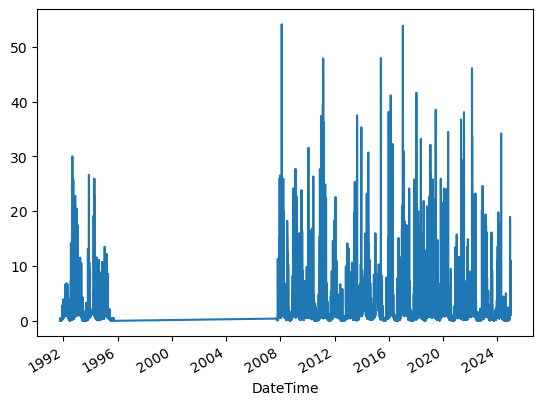

In [12]:
%%time


# read the 'water_quality' data using hive partitioning    
dataset = ds.dataset(
    files['streamflow'],
    format="parquet",
    filesystem=hs.get_s3_filesystem(),
    partitioning="hive"
)

# filter these data for the stream ids returned when we queried the metadata file
stream_ids = list(dat.STREAM_ID) 
result = dataset.to_table(
    filter=(
        (ds.field("STREAM_ID").isin(stream_ids))
    )
)
df = result.to_pandas()

for group_name, group_df in df.groupby(df.STREAM_ID):
    group_df.set_index('DateTime', inplace=True)
    group_df.Q_m3s.plot()

In [13]:
df.STREAM_ID.unique()

<ArrowStringArray>
['STREAM-gauge-1730']
Length: 1, dtype: str